# Temporal input: what the checks establish

This report reads saved aggregate evidence. The question is whether the actual-year versus held-year comparison changes when query times use the same context-based scaling as joint inference. The approved scope is the primary `last_3` panel on CPU. Shared 2008 and 2009 builds retain their historical `all_history` names because they also serve `last_3`; the separate all-history robustness panel is dropped.

The original predictor, clinical rows, reference explanations and thresholds remain fixed. Results below are retrospective; they are not clinical validation or a measure of patient uncertainty.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 100)

# Prefer CPU-primary evidence and retain the earlier CUDA evidence separately.
CPU_ROOT = next((path for path in (
    Path("analysis_outputs/temporal_input_attribution/checks_cpu_primary"),
    Path("stats/concept_agreement_study/extensions/temporal_input_attribution/checks_cpu_primary"),
) if all((path / name).is_file() for name in ("provenance.json", "coverage.csv", "parity.csv", "historical-replay.csv", "timing.json"))), None)
CUDA_ROOT = next((path for path in (
    Path("analysis_outputs/temporal_input_attribution/checks"),
    Path("stats/concept_agreement_study/extensions/temporal_input_attribution/checks"),
) if all((path / name).is_file() for name in ("provenance.json", "coverage.csv", "parity.csv", "historical-replay.csv", "timing.json"))), None)
REPORT_ROOT = CPU_ROOT or CUDA_ROOT
if REPORT_ROOT is None:
    raise FileNotFoundError("Saved temporal input checks are not available")
PANEL_ROOT = REPORT_ROOT.parent
provenance = json.loads((REPORT_ROOT / "provenance.json").read_text())
coverage_all = pd.read_csv(REPORT_ROOT / "coverage.csv")
coverage = coverage_all.loc[coverage_all["aliases"].str.split(",").apply(lambda values: "last_3" in values)].copy()
def saved_table(name):
    try:
        return pd.read_csv(REPORT_ROOT / name)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()
parity = saved_table("parity.csv")
replay = saved_table("historical-replay.csv")
timing = json.loads((REPORT_ROOT / "timing.json").read_text())
print(f"Saved checks: {REPORT_ROOT}")
print("CPU primary checks:", "available" if CPU_ROOT else "not yet saved")
print("Earlier CUDA checks:", "available as historical evidence" if CUDA_ROOT else "not available")

Saved checks: stats/concept_agreement_study/extensions/temporal_input_attribution/checks_cpu_primary
CPU primary checks: available
Earlier CUDA checks: available as historical evidence


## Frozen inputs and coverage

The ledger uses the complete build, reference year and factor-family identity. Early aliases share a predictor and are counted once. An absent CAV measurement does not by itself remove a concept from rule or activation measurements.

In [2]:
systems_all = pd.DataFrame(provenance["systems"])
systems = systems_all.loc[systems_all["variants"].apply(lambda values: "last_3" in values)].copy()
checks = provenance["checks"]
summary = pd.DataFrame([
    {"Measure": "Retained primary predictor systems", "Count": len(systems)},
    {"Measure": "Retained primary full-key concepts", "Count": len(coverage)},
    {"Measure": "Current checkpoint matches recorded checkpoint", "Count": int(systems["current_checkpoint_matches"].sum())},
    {"Measure": "Concepts with a strict-cutoff disagreement", "Count": int((coverage["sae_cutoff_disagreements"] > 0).sum())},
    {"Measure": "Strict-cutoff disagreements", "Count": int(coverage["sae_cutoff_disagreements"].sum())},
])
display(summary)
if CUDA_ROOT:
    historical = json.loads((CUDA_ROOT / "provenance.json").read_text())
    historical_coverage = pd.read_csv(CUDA_ROOT / "coverage.csv")
    print(f"Earlier broader CUDA audit: {len(historical['systems'])} systems, {len(historical_coverage)} concepts, "
          f"{int(historical_coverage['sae_cutoff_disagreements'].sum())} strict-cutoff disagreements.")

unsupported = coverage.loc[coverage["fit_positive"].eq(0),
    ["concept", "aliases", "fit_positive", "cav_support_status"]]
print("Concepts with zero reference CAV-fitting positives (retained in the ledger):")
display(unsupported)

,Measure,Count
0,Retained primary predictor systems,7
1,Retained primary full-key concepts,62
2,Current checkpoint matches recorded checkpoint,7
3,Concepts with a strict-cutoff disagreement,2
4,Strict-cutoff disagreements,5


Earlier broader CUDA audit: 11 systems, 95 concepts, 13 strict-cutoff disagreements.
Concepts with zero reference CAV-fitting positives (retained in the ledger):


,concept,aliases,fit_positive,cav_support_status
43,"last_3/2012/2012/42/42:254,135:190,215:74",last_3,0,unsupported


## Frozen activation replay and cutoff boundaries

For this archive audit, the saved historical activation and its original strict cutoff define the mask. In the scientific comparison, each fresh arm uses its own freshly encoded activation and the same original strict cutoff. Reapplying each original scaler and SAE to the archived raw embeddings reproduces the activation within the prescribed floating-point tolerance, but a small numerical difference can cross a cutoff. These are counts of disagreements, not a new threshold or a reason to discard a concept.

,Concept,Build,Reference year,Disagreements,Largest error among disagreements,Largest activation error
14,"all_history/2009/2009/42/42:134,135:207,215:5",all_history,2009,4,9.536743e-07,0.000002
32,"last_3/2011/2011/42/42:49,135:91,215:140",last_3,2011,1,3.576279e-07,0.000001


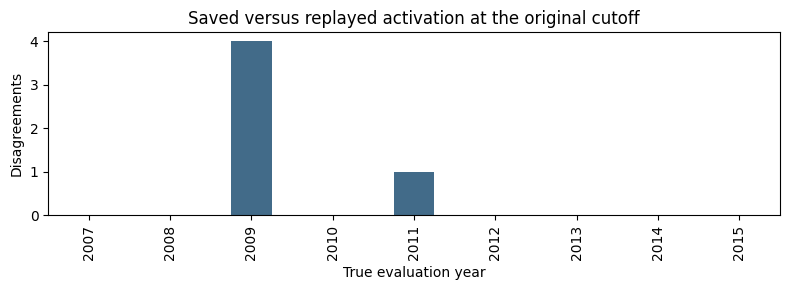

In [3]:
boundary = coverage.loc[coverage["sae_cutoff_disagreements"] > 0,
    ["concept", "build", "reference", "sae_cutoff_disagreements",
     "sae_disagreement_max_abs_error", "sae_replay_max_abs_error"]].copy()
boundary.columns = ["Concept", "Build", "Reference year", "Disagreements",
                    "Largest error among disagreements", "Largest activation error"]
display(boundary)

year_counts = {}
for item in coverage["sae_cutoff_disagreements_by_year"]:
    for year, count in json.loads(item).items():
        year_counts[int(year)] = year_counts.get(int(year), 0) + int(count)
year_counts = pd.Series(year_counts, name="Disagreements").sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
year_counts.plot.bar(ax=ax, color="#426b89")
ax.set(xlabel="True evaluation year", ylabel="Disagreements", title="Saved versus replayed activation at the original cutoff")
fig.tight_layout()
plt.show()

## Matched cached and joint checks

Each check uses the first outcome-blind saved row for each true evaluation year and supplied-year setting. Current CPU checks pack those rows into one shared cached/joint batch per system; earlier CUDA checks used separate single-row batches. Each saved parity row is one year/input probe setting within that system-level check, not an independent inference batch. The cached and joint paths reuse the recorded clinical transform, feature shuffle and configuration; their observed query features, temporal input, probabilities and decoder embeddings are compared. Parity uses the combined rtol=1e-4 and atol=1e-5 check; the saved error columns report maximum absolute errors only. A pass here is a numerical check for those probe settings, not evidence that all systems or patients have passed.

In [4]:
error_by_system = {(row["build"], int(row["reference"])): row["error"] for row in timing["errors"]}
parity_counts = parity.groupby(["build", "reference"]).agg(
    probe_settings=("parity", "size"), passed_probe_settings=("parity", lambda values: int((values == "pass").sum())),
    probability_max_error=("probability_max_abs_error", "max"),
    embedding_max_error=("embedding_max_abs_error", "max"),
).reset_index() if not parity.empty else pd.DataFrame(columns=["build", "reference", "probe_settings", "passed_probe_settings", "probability_max_error", "embedding_max_error"])
parity_by_system = {(row.build, int(row.reference)): row for row in parity_counts.itertuples(index=False)}
system_rows = []
for system in provenance["systems"]:
    if "last_3" not in system["variants"]:
        continue
    key = (system["build"], int(system["reference"]))
    result = parity_by_system.get(key)
    error = error_by_system.get(key)
    status = ("out of GPU memory" if error and "OutOfMemoryError" in error
              else "GPU memory guard" if error and "Memory usage" in error
              else "check error" if error else "checked" if result else "not checked")
    system_rows.append({"Build": key[0], "Reference": key[1], "Context years": ", ".join(map(str, system["context_years"])),
                        "Context rows": system["context_rows"], "Result": status,
                        "Passed probe settings": int(result.passed_probe_settings) if result else 0,
                        "Checked probe settings": int(result.probe_settings) if result else 0,
                        "Historical device": system["saved_device"],
                        "Recorded historical batch size": system["saved_batch_rows"]})
display(pd.DataFrame(system_rows).sort_values(["Reference", "Build"]))
if parity.empty:
    print("No parity batches were saved for the selected checks.")
else:
    retained = {(row["build"], int(row["reference"])) for row in provenance["systems"] if "last_3" in row["variants"]}
    primary_parity = parity.loc[[(row.build, int(row.reference)) in retained for row in parity.itertuples(index=False)]]
    print(f"Primary matched year/input probe settings passed: {(primary_parity['parity'] == 'pass').sum()} of {len(primary_parity)}")
    print(f"Largest probability error: {primary_parity['probability_max_abs_error'].max():.3g}")
    print(f"Largest embedding error: {primary_parity['embedding_max_abs_error'].max():.3g}")
    display(primary_parity[["build", "reference", "year", "input", "rows", "parity", "clinical_features_equal",
                            "categorical_indices_equal", "time_max_abs_error", "probability_max_abs_error", "embedding_max_abs_error"]])

,Build,Reference,Context years,Context rows,Result,Passed probe settings,Checked probe settings,Historical device,Recorded historical batch size
6,r1,2007,2007,946,checked,16,16,cuda,4096
0,all_history,2008,"2007, 2008",3091,checked,14,14,cpu,4096
1,all_history,2009,"2007, 2008, 2009",5520,checked,12,12,cpu,4096
2,last_3,2010,"2008, 2009, 2010",6153,checked,10,10,cpu,4096
3,last_3,2011,"2009, 2010, 2011",6303,checked,8,8,cpu,4096
4,last_3,2012,"2010, 2011, 2012",6329,checked,6,6,cpu,4096
5,last_3,2013,"2011, 2012, 2013",6276,checked,4,4,cpu,4096


Primary matched year/input probe settings passed: 70 of 70
Largest probability error: 2.38e-07
Largest embedding error: 0


,build,reference,year,input,rows,parity,clinical_features_equal,categorical_indices_equal,time_max_abs_error,probability_max_abs_error,embedding_max_abs_error
0,all_history,2008,2008,actual,1,pass,True,True,0.0,1.117587e-08,0.0
1,all_history,2008,2008,held,1,pass,True,True,0.0,1.117587e-08,0.0
2,all_history,2008,2009,actual,1,pass,True,True,0.0,8.940697e-08,0.0
3,all_history,2008,2009,held,1,pass,True,True,0.0,0.000000e+00,0.0
4,all_history,2008,2010,actual,1,pass,True,True,0.0,0.000000e+00,0.0
5,all_history,2008,2010,held,1,pass,True,True,0.0,6.519258e-09,0.0
6,all_history,2008,2011,actual,1,pass,True,True,0.0,5.960464e-08,0.0
7,all_history,2008,2011,held,1,pass,True,True,0.0,2.384186e-07,0.0
8,all_history,2008,2012,actual,1,pass,True,True,0.0,1.192093e-07,0.0
9,all_history,2008,2012,held,1,pass,True,True,0.0,0.000000e+00,0.0


## Historical execution identity

The current-source reconstruction is compared with saved probabilities and, for actual-year inputs, saved raw embeddings. It uses singleton batches and is not an exact replay of the recorded historical batch schedule. In the seven-system CPU check, 15 of 70 archived probability rows and 8 of 35 actual-year raw-embedding rows exceeded the stated floating-point tolerance. The largest absolute errors were 0.0011048317 for probability and 0.01336386 for raw embedding. The held-year archive does not contain raw embeddings. These are observed reconstruction mismatches, not evidence of a normalization effect.

The recorded batch sizes are shown above. The historical TabPFN build is unknown in the run manifests; the recorded pilot source hash differs from the current source for the 2007 reference system. Together with the singleton schedule and reconstruction mismatches, these limits prevent a historical normalization attribution. The numerical parity check between fresh cached and joint paths is reported separately above.

In [5]:
historical_sources = systems[["build", "reference", "current_pilot_source_matches", "historical_tabpfn_package", "saved_device", "saved_batch_rows"]].copy()
historical_sources.columns = ["Build", "Reference", "Current pilot source matches", "Historical TabPFN build", "Historical device", "Recorded batch size"]
display(historical_sources.sort_values(["Reference", "Build"]))
if not replay.empty:
    retained = {(row["build"], int(row["reference"])) for row in provenance["systems"] if "last_3" in row["variants"]}
    primary_replay = replay.loc[[(row.build, int(row.reference)) in retained for row in replay.itertuples(index=False)]]
    display(primary_replay[["build", "reference", "year", "input", "kind", "probability_max_abs_error",
                            "probability_within_fp32_tolerance", "embedding_max_abs_error", "embedding_within_fp32_tolerance", "held_embedding_status"]])
else:
    print("No historical reconstruction batches were saved for the selected checks.")
print("Scoring gate:", "ready" if checks["ready_for_scoring"] else "not ready")
print("Historical replay:", checks["historical_exact_replay"])

,Build,Reference,Current pilot source matches,Historical TabPFN build,Historical device,Recorded batch size
6,r1,2007,False,unknown,cuda,4096
0,all_history,2008,True,unknown,cpu,4096
1,all_history,2009,True,unknown,cpu,4096
2,last_3,2010,True,unknown,cpu,4096
3,last_3,2011,True,unknown,cpu,4096
4,last_3,2012,True,unknown,cpu,4096
5,last_3,2013,True,unknown,cpu,4096


,build,reference,year,input,kind,probability_max_abs_error,probability_within_fp32_tolerance,embedding_max_abs_error,embedding_within_fp32_tolerance,held_embedding_status
0,all_history,2008,2008,actual,current_source_reconstruction_not_exact_historical_batch,8.195639e-07,True,0.000013,True,not applicable
1,all_history,2008,2008,held,current_source_reconstruction_not_exact_historical_batch,8.195639e-07,True,NaN,NaN,not archived
2,all_history,2008,2009,actual,current_source_reconstruction_not_exact_historical_batch,1.132488e-06,True,0.000006,True,not applicable
3,all_history,2008,2009,held,current_source_reconstruction_not_exact_historical_batch,1.326203e-06,True,NaN,NaN,not archived
4,all_history,2008,2010,actual,current_source_reconstruction_not_exact_historical_batch,3.725290e-08,True,0.000005,True,not applicable
5,all_history,2008,2010,held,current_source_reconstruction_not_exact_historical_batch,7.450581e-08,True,NaN,NaN,not archived
6,all_history,2008,2011,actual,current_source_reconstruction_not_exact_historical_batch,4.470348e-07,True,0.000002,True,not applicable
7,all_history,2008,2011,held,current_source_reconstruction_not_exact_historical_batch,7.450581e-07,True,NaN,NaN,not archived
8,all_history,2008,2012,actual,current_source_reconstruction_not_exact_historical_batch,5.587935e-07,True,0.000007,True,not applicable
9,all_history,2008,2012,held,current_source_reconstruction_not_exact_historical_batch,1.862645e-08,True,NaN,NaN,not archived


Scoring gate: not ready
Historical replay: unavailable: singleton current-source reconstruction does not reproduce the recorded historical batch schedule


## Four-cell results, when available

For a frozen rule, agreement is the share of rule-positive patients whose frozen factor activation is strictly above its original cutoff. Let H be historical processing and N consistent processing. For each concept and year, `d_H` and `d_N` are actual-year minus held-year agreement; `d_N − d_H` is their difference. Uncertainty, when available, uses the same patient multiplicity across cells, years, systems and concepts and is conditional on the frozen objects.

The tables below read only saved aggregate panels. They include cell denominators and intervals, original-threshold death outcomes, probability separately from predictive entropy, and embedding displacement. Missing years and unavailable metrics remain visible. AUROC and Brier are descriptive.

In [6]:
panel_paths = {name: PANEL_ROOT / name / "aggregate.json" for name in ("primary",)}
panel_summaries = []
for panel_name, path in panel_paths.items():
    if not path.is_file():
        panel_summaries.append({"Panel": panel_name, "Status": "No saved scientific panel"})
        continue
    panel = json.loads(path.read_text())
    cases = panel.get("cases", [])
    panel_summaries.append({"Panel": panel_name, "Status": "Saved aggregate loaded", "Rows": len(cases)})
    cells_out, contrasts_out, changes_out, unavailable = [], [], [], []
    support_out, contrast_support_out, change_support_out = [], [], []
    cases_by_year = {(item.get("concept"), item.get("reference"), item.get("year")): item for item in cases}
    cell_metrics = ("agreement", "rule_f2", "mean_probability", "mean_entropy", "mean_activation",
                    "false_positives", "false_negatives", "caught_deaths", "false_positive_rate",
                    "false_negative_rate", "death_f1", "brier", "auroc")
    contrast_metrics = ("agreement", "mean_probability", "mean_entropy", "mean_activation",
                        "false_positives", "false_negatives", "caught_deaths", "death_f1", "embedding_displacement")
    for case in cases:
        identity = {"Concept": case.get("concept"), "Build": case.get("build"),
                    "Reference": case.get("reference"), "Year": case.get("year")}
        if "unavailable_reason" in case:
            unavailable.append({**identity, "Reason": case["unavailable_reason"]})
            continue
        for cell_name, metrics in case.get("cells", {}).items():
            support_out.append({**identity, "Cell": cell_name,
                                "Patients": metrics.get("patients", {}).get("estimate"),
                                "Deaths": metrics.get("deaths", {}).get("estimate"),
                                "Survivors": metrics.get("survivors", {}).get("estimate")})
            for metric in cell_metrics:
                if metric in metrics:
                    value = metrics[metric]
                    cells_out.append({**identity, "Cell": cell_name, "Metric": metric,
                                      "Estimate": value.get("estimate"), "Numerator": value.get("numerator"),
                                      "Denominator": value.get("denominator"), "Low": value.get("low"),
                                      "High": value.get("high"), "Valid draws": value.get("valid_draws"),
                                      "Unavailable reason": value.get("reason")})
        for metric in contrast_metrics:
            for contrast, value in case.get("contrasts", {}).get(metric, {}).items():
                contrasts_out.append({**identity, "Metric": metric, "Contrast": contrast,
                                      "Estimate": value.get("estimate"), "Numerator": value.get("numerator"),
                                      "Denominator": value.get("denominator"), "Low": value.get("low"),
                                      "High": value.get("high"), "Valid draws": value.get("valid_draws"),
                                      "Unavailable reason": value.get("reason")})
                for component, support in value.get("components", {}).items():
                    cohort = case.get("cells", {}).get(component, {})
                    contrast_support_out.append({**identity, "Metric": metric, "Contrast": contrast,
                                                 "Cell": component, "Numerator": support.get("numerator"),
                                                 "Denominator": support.get("denominator"),
                                                 "Patients": cohort.get("patients", {}).get("estimate"),
                                                 "Deaths": cohort.get("deaths", {}).get("estimate"),
                                                 "Survivors": cohort.get("survivors", {}).get("estimate")})
        change = case.get("reference_to_later") or {}
        for cell_name, metrics in change.get("cells", {}).items():
            for metric in cell_metrics:
                if metric in metrics:
                    value = metrics[metric]
                    changes_out.append({**identity, "Cell": cell_name, "Metric": metric,
                                        "Change from reference": value.get("estimate"),
                                        "Reference denominator": value.get("reference", {}).get("denominator"),
                                        "Later denominator": value.get("later", {}).get("denominator"),
                                        "Low": value.get("low"), "High": value.get("high"),
                                        "Valid draws": value.get("valid_draws"), "Unavailable reason": value.get("reason")})
        for metric in contrast_metrics:
            for contrast, value in change.get("contrasts", {}).get(metric, {}).items():
                changes_out.append({**identity, "Cell": contrast, "Metric": metric,
                                    "Change from reference": value.get("estimate"),
                                    "Reference denominator": None, "Later denominator": None,
                                    "Low": value.get("low"), "High": value.get("high"),
                                    "Valid draws": value.get("valid_draws"), "Unavailable reason": value.get("reason")})
                reference_case = cases_by_year.get((case.get("concept"), case.get("reference"), case.get("reference")), {})
                for period, period_case in (("reference", reference_case), ("later", case)):
                    for component, support in value.get(period, {}).get("components", {}).items():
                        cohort = period_case.get("cells", {}).get(component, {})
                        change_support_out.append({**identity, "Metric": metric, "Contrast": contrast,
                                                   "Period": period, "Cell": component,
                                                   "Numerator": support.get("numerator"), "Denominator": support.get("denominator"),
                                                   "Patients": cohort.get("patients", {}).get("estimate"),
                                                   "Deaths": cohort.get("deaths", {}).get("estimate"),
                                                   "Survivors": cohort.get("survivors", {}).get("estimate")})
    print(f"{panel_name}: patient and outcome support by cell")
    display(pd.DataFrame(support_out))
    print(f"{panel_name}: four-cell measures")
    display(pd.DataFrame(cells_out))
    print(f"{panel_name}: paired contrasts and embedding displacement")
    display(pd.DataFrame(contrasts_out))
    print(f"{panel_name}: support for each contrast component")
    display(pd.DataFrame(contrast_support_out))
    print(f"{panel_name}: changes from the reference year")
    display(pd.DataFrame(changes_out))
    print(f"{panel_name}: reference and later contrast component support")
    display(pd.DataFrame(change_support_out))
    print(f"{panel_name}: unavailable coverage")
    display(pd.DataFrame(unavailable))
display(pd.DataFrame(panel_summaries))

,Panel,Status
0,primary,No saved scientific panel


## What remains unresolved

In the earlier broader CUDA check, ten of eleven systems could not complete because of memory limits. The approved scope retains seven primary systems and uses CPU; the separate all-history robustness panel is dropped. The shared 2008 and 2009 builds remain in the primary panel. The bounded CPU check completed all seven systems and all 70 year/input probe settings passed fresh cached/joint parity. This establishes feasibility for these bounded checks, not for an unapproved full scientific panel. Current-source archival reconstruction mismatches, the unknown historical dependency build and the singleton replay schedule prevent historical normalization attribution. No full scientific panel has been run.

This analysis does not fit new explanations or recalibrate mortality thresholds. It does not estimate a clinical attribution fraction, independent fitting uncertainty, equal-alarm performance, a paired AUROC-difference interval, or a history-plus-risk forecasting comparison.

In [7]:
# Public inputs are aggregate tables and metadata; patient-level arrays are never read here.
for name, frame in (("coverage", coverage), ("parity", parity), ("historical replay", replay)):
    forbidden = {"patient_id", "patient_ids", "per_patient"} & set(frame.columns)
    if forbidden:
        raise ValueError(f"{name} contains patient-level columns: {sorted(forbidden)}")
print("Public table column check passed. No private patient arrays were opened.")

Public table column check passed. No private patient arrays were opened.
